In [19]:
import torch, transformers
print('Mansi Dhamne')
print('torch:', torch.__version__)
print('transformers:', transformers.__version__)

Mansi Dhamne
torch: 2.14.1+cu130
transformers: 5.22.1


# 3.1 Reading Pythia

### 3.1.1 **Why checkpoints?**

- The gender-bias intervention depends most directly on Pythia’s design. The authors resume training from an intermediate checkpoint and replay the same training data in the same order, changing selected gendered pronouns to isolate their effect (Sec 3.1).

- The memorization study could mostly be done with the final model and a record of the training data order. The authors test which training sequences the model reproduces and map those sequences back to where they appeared in training (Sec 3.2)

### 3.1.2 . Data

In Sec 2.6, the authors report that deduplicating the Pile did not clearly improve Pythia’s language modeling performance. They suggest that deliberately sampling some Pile subsets more often may have different effects from ordinary data duplication. They also suggest that the gains reported in earlier studies may depend on the quality of the datasets those studies used.

# 3.2.1 Logit Lens: Watching Predictions Form Layer by Layer

In [20]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from transformers import AutoTokenizer, GPTNeoXForCausalLM

MODEL_NAME = "EleutherAI/pythia-160m-deduped"
REVISION = "step143000"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=REVISION)
model = GPTNeoXForCausalLM.from_pretrained(
    MODEL_NAME, revision=REVISION, torch_dtype=torch.float32
).to(device).eval()

num_layers = model.config.num_hidden_layers
assert num_layers == 12

final_norm = model.gpt_neox.final_layer_norm
unembed = model.get_output_embeddings()

@torch.inference_mode()
def check_final_layer_norm():
    ids = tokenizer(
        "My fellow Americans", return_tensors="pt", add_special_tokens=False
    ).input_ids.to(device)

    output = model(ids, output_hidden_states=True, use_cache=False)
    last_state = output.hidden_states[-1]

    direct = unembed(last_state)
    normalized = unembed(final_norm(last_state))

    if torch.allclose(direct, output.logits, atol=1e-4, rtol=1e-4):
        print("Final hidden state already includes layer norm.")
        return True
    if torch.allclose(normalized, output.logits, atol=1e-4, rtol=1e-4):
        print("Final hidden state needs layer norm before unembedding.")
        return False

    raise RuntimeError("Neither final-layer readout matches the model logits.")


final_state_is_normalized = check_final_layer_norm()


def lens_logits(hidden_state, layer):
    if layer != num_layers or not final_state_is_normalized:
        hidden_state = final_norm(hidden_state)
    return unembed(hidden_state)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Final hidden state already includes layer norm.


Sentence length: 11 tokenizer tokens


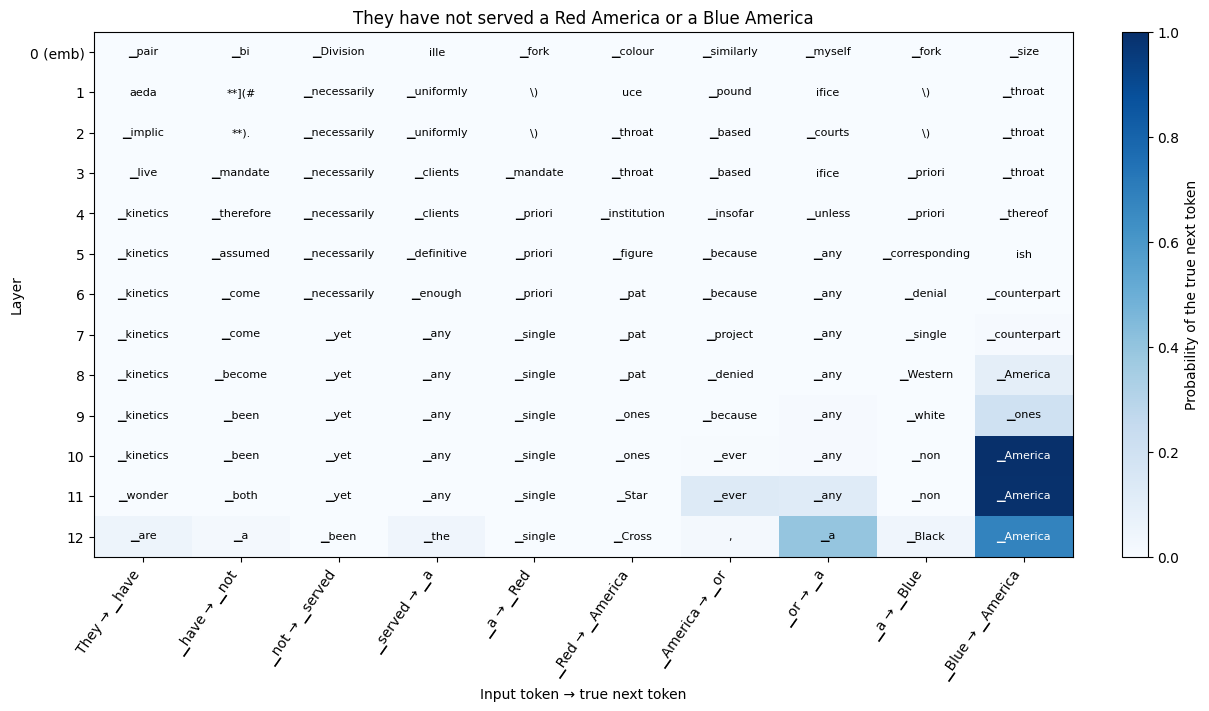

In [21]:
def token_label(token_id):
    return tokenizer.decode([int(token_id)]).replace(" ", "▁").replace("\n", "↵")


@torch.inference_mode()
def plot_lens_grid(sentence):
    ids = tokenizer(
        sentence, return_tensors="pt", add_special_tokens=False
    ).input_ids.to(device)

    inputs = ids[:, :-1]
    targets = ids[0, 1:]
    states = model.gpt_neox(
        inputs, output_hidden_states=True, use_cache=False
    ).hidden_states

    num_positions = targets.numel()
    probabilities = np.empty((num_layers + 1, num_positions))
    predictions = []

    for layer, state in enumerate(states):
        logits = lens_logits(state, layer)[0]
        target_logits = logits.gather(1, targets[:, None]).squeeze(1)
        probabilities[layer] = (
            target_logits - logits.logsumexp(dim=-1)
        ).exp().cpu().numpy()
        predictions.append([token_label(t) for t in logits.argmax(dim=-1).tolist()])

    fig, ax = plt.subplots(
        figsize=(max(12, 1.1 * num_positions), 7), layout="constrained"
    )
    image = ax.imshow(probabilities, cmap="Blues", vmin=0, vmax=1, aspect="auto")

    for layer, row in enumerate(predictions):
        for pos, prediction in enumerate(row):
            ax.text(
                pos, layer, prediction, ha="center", va="center", fontsize=8,
                color="white" if probabilities[layer, pos] > 0.55 else "black",
            )

    input_labels = [token_label(t) for t in inputs[0].tolist()]
    target_labels = [token_label(t) for t in targets.tolist()]
    ax.set_xticks(
        range(num_positions),
        [f"{x} → {y}" for x, y in zip(input_labels, target_labels)],
        rotation=55, ha="right",
    )
    ax.set_yticks(range(num_layers + 1), ["0 (emb)"] + list(range(1, num_layers + 1)))
    ax.set_xlabel("Input token → true next token")
    ax.set_ylabel("Layer")
    ax.set_title(sentence)
    fig.colorbar(image, ax=ax, label="Probability of the true next token")
    print(f"Sentence length: {ids.shape[1]} tokenizer tokens")
    plt.show()


plot_lens_grid("They have not served a Red America or a Blue America")

Sentence length: 13 tokenizer tokens


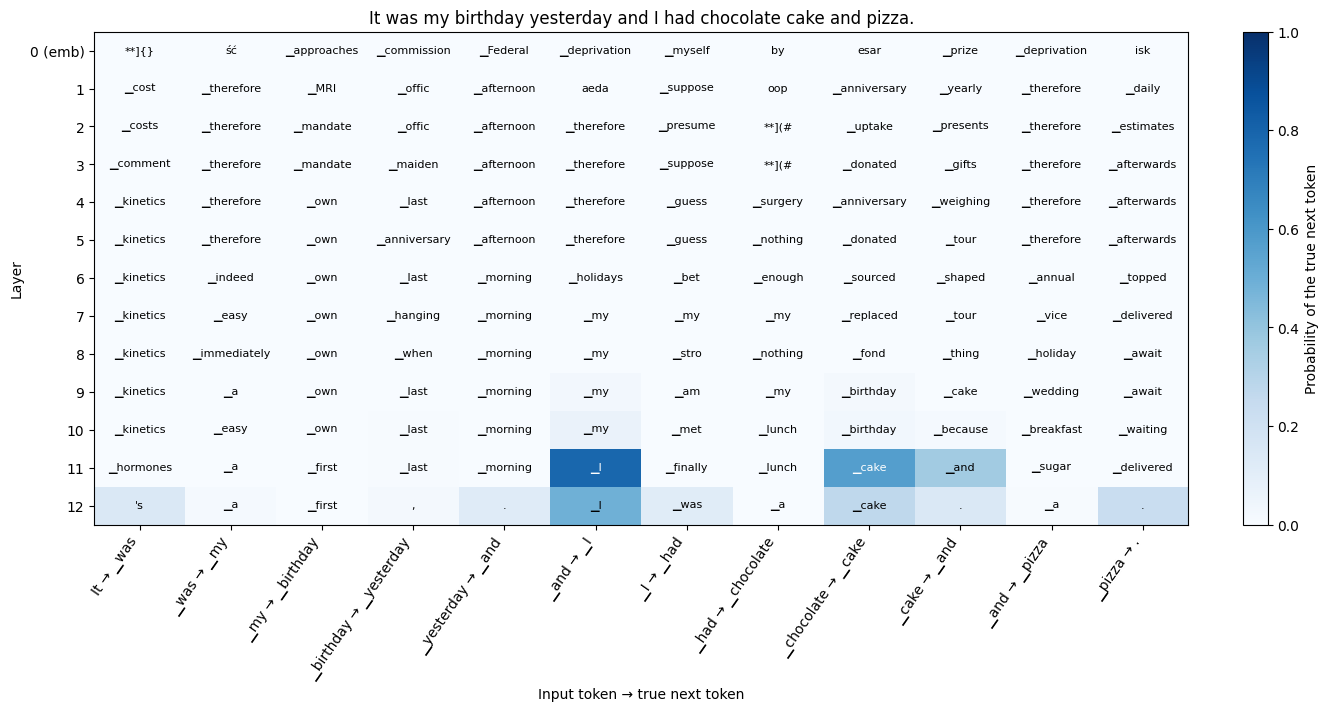

In [22]:
plot_lens_grid("It was my birthday yesterday and I had chocolate cake and pizza.")

### Evaluate top-1 accuracy over the full Obama test file

Total next-token targets: 6,016
Layer  0: 1/6016 = 0.000166223404 (0.017%)
Layer  6: 332/6016 = 0.055186170213 (5.519%)
Layer 12: 2116/6016 = 0.351728723404 (35.173%)


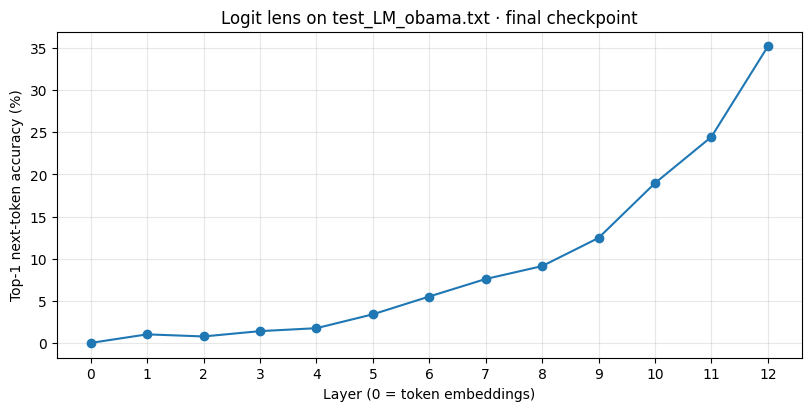

In [23]:
test_path = Path("speechesdataset/test_LM_obama.txt")
if not test_path.is_file():
    test_path = Path("test_LM_obama.txt")

test_text = test_path.read_text(encoding="utf-8")
test_ids = tokenizer(
    test_text, add_special_tokens=False, return_attention_mask=False
).input_ids
test_ids = torch.tensor(test_ids, dtype=torch.long)

block_size = 256
correct = np.zeros(num_layers + 1, dtype=np.int64)
total = 0

with torch.inference_mode():
    for start in range(0, test_ids.numel() - 1, block_size):
        stop = min(start + block_size, test_ids.numel() - 1)
        inputs = test_ids[start:stop].unsqueeze(0).to(device)
        targets = test_ids[start + 1:stop + 1].to(device)

        states = model.gpt_neox(
            inputs, output_hidden_states=True, use_cache=False
        ).hidden_states

        for layer, state in enumerate(states):
            predicted = lens_logits(state, layer)[0].argmax(dim=-1)
            correct[layer] += (predicted == targets).sum().item()

        total += targets.numel()

assert total == test_ids.numel() - 1
accuracy = correct / total

print(f"Total next-token targets: {total:,}")
for layer in (0, 6, 12):
    print(
        f"Layer {layer:2d}: {correct[layer]}/{total} "
        f"= {accuracy[layer]:.12f} ({accuracy[layer]:.3%})"
    )

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(range(num_layers + 1), 100 * accuracy, marker="o")
ax.set_xticks(range(num_layers + 1))
ax.set_xlabel("Layer (0 = token embeddings)")
ax.set_ylabel("Top-1 next-token accuracy (%)")
ax.set_title("Logit lens on test_LM_obama.txt · final checkpoint")
ax.grid(alpha=0.3)
plt.show()

# 3.2.2 The Logit Lens: Accuracy by Layer Curve For Different Steps Across Training

Evaluating step512...


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Evaluating step1000...


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Evaluating step8000...


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

   step512 layer0: 0.0499% layer 6: 11.5525%  layer 12: 20.6782%
  step1000 layer0: 0.0332% layer 6: 15.8910%  layer 12: 24.8005%
  step8000 layer0: 0.0499% layer 6: 15.8411%  layer 12: 33.8431%
step143000 layer0: 0.0166% layer 6: 5.5186%  layer 12: 35.1729%


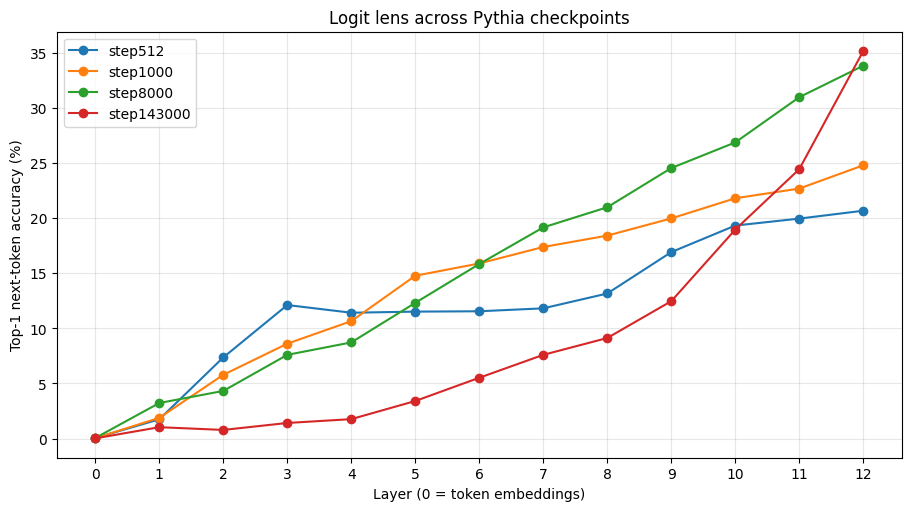

In [24]:
import gc


@torch.inference_mode()
def checkpoint_lens_accuracy(checkpoint):
    backbone = checkpoint.gpt_neox
    norm = backbone.final_layer_norm
    head = checkpoint.get_output_embeddings()

    # Verify whether the returned last hidden state already includes final norm.
    probe = test_ids[:16].unsqueeze(0).to(device)
    output = checkpoint(probe, output_hidden_states=True, use_cache=False)
    last = output.hidden_states[-1]
    already_normalized = torch.allclose(
        head(last), output.logits, atol=1e-4, rtol=1e-4
    )
    torch.testing.assert_close(
        head(last if already_normalized else norm(last)),
        output.logits,
        atol=1e-4,
        rtol=1e-4,
    )

    correct = np.zeros(num_layers + 1, dtype=np.int64)
    total = test_ids.numel() - 1

    for start in range(0, total, block_size):
        stop = min(start + block_size, total)
        inputs = test_ids[start:stop].unsqueeze(0).to(device)
        targets = test_ids[start + 1:stop + 1].to(device)
        states = backbone(
            inputs, output_hidden_states=True, use_cache=False
        ).hidden_states

        for layer, state in enumerate(states):
            if layer != num_layers or not already_normalized:
                state = norm(state)
            predicted = head(state)[0].argmax(dim=-1)
            correct[layer] += (predicted == targets).sum().item()

    return correct / total

curves = {"step143000": accuracy}

for step in ("step512", "step1000", "step8000"):
    print(f"Evaluating {step}...", flush=True)
    checkpoint = GPTNeoXForCausalLM.from_pretrained(
        MODEL_NAME, revision=step, torch_dtype=torch.float32
    ).to(device).eval()
    curves[step] = checkpoint_lens_accuracy(checkpoint)
    del checkpoint
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for step in ("step512", "step1000", "step8000", "step143000"):
    curve = curves[step]
    ax.plot(range(num_layers + 1), 100 * curve, marker="o", label=step)
    print(f"{step:>10} layer0: {curve[0]:.4%} layer 6: {curve[6]:.4%}  layer 12: {curve[12]:.4%}")

ax.set_xticks(range(num_layers + 1))
ax.set_xlabel("Layer (0 = token embeddings)")
ax.set_ylabel("Top-1 next-token accuracy (%)")
ax.set_title("Logit lens across Pythia checkpoints")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

The middle layers become more readable early in training, but much less readable by the final checkpoint. At layer 6, accuracy rises from about 11.6% at step512 to 15.8% at step8000, then falls to about 5.5% at step143000. Meanwhile, final-layer accuracy improves from about 20.7% to 35.2%. At the final checkpoint, most of the improvement occurs in the last few layers.

This suggests that later training makes intermediate representations less directly aligned with the final layer norm and unembedding used by the logit lens. The middle hidden states increasingly use a different representational “language,” which later layers transform into a form the output readout can interpret. Their lower lens accuracy therefore reflects reduced accessibility through this readout, even as the model’s final predictions improve.

# 3.3 Transplanting Layers Across Time


In [28]:
import torch.nn.functional as F

final_model = GPTNeoXForCausalLM.from_pretrained(
    MODEL_NAME,
    revision="step143000",
    torch_dtype=torch.float32,
).to(device).eval()

donor_steps = ["step0", "step1000", "step8000", "step32000"]
component_names = (
    ["Embedding"]
    + [f"Layer {i+1}" for i in range(12)]
    + ["Unembedding"]
)

# Confirm that replacing one embedding matrix cannot also change the other.
assert (
    final_model.get_input_embeddings().weight.data_ptr()
    != final_model.get_output_embeddings().weight.data_ptr()
)

evaluation_block_size = 256

@torch.inference_mode()
def mean_test_loss(checkpoint):
    """Mean next-token negative log likelihood over the full test file."""
    total_nll = 0.0
    total_targets = 0

    for start in range(0, test_ids.numel() - 1, evaluation_block_size):
        stop = min(start + evaluation_block_size, test_ids.numel() - 1)
        inputs = test_ids[start:stop].unsqueeze(0).to(device)
        targets = test_ids[start + 1:stop + 1].to(device)

        logits = checkpoint(inputs, use_cache=False).logits[0]
        total_nll += F.cross_entropy(
            logits, targets, reduction="sum"
        ).item()
        total_targets += targets.numel()

    assert total_targets == test_ids.numel() - 1
    return total_nll / total_targets


def get_component(checkpoint, index):
    if index == 0:
        return checkpoint.get_input_embeddings()
    if index == 13:
        return checkpoint.get_output_embeddings()
    return checkpoint.gpt_neox.layers[index - 1]


baseline_loss = mean_test_loss(final_model)
transplant_losses = np.zeros((14, 4), dtype=np.float64)

print(f"Intact final-model loss: {baseline_loss:.12f} nats/token")

for column, step in enumerate(donor_steps):
    # Keep donor weights on CPU. load_state_dict copies them to the target device.
    donor = GPTNeoXForCausalLM.from_pretrained(
        MODEL_NAME,
        revision=step,
        torch_dtype=torch.float32,
    ).eval()

    for row, component_name in enumerate(component_names):
        target = get_component(final_model, row)
        donor_component = get_component(donor, row)

        # Clone because state_dict normally contains references to live weights.
        original = {
            key: value.detach().cpu().clone()
            for key, value in target.state_dict().items()
        }

        try:
            target.load_state_dict(donor_component.state_dict())
            transplant_losses[row, column] = mean_test_loss(final_model)
        finally:
            # Restore even if evaluation raises an exception.
            target.load_state_dict(original)

        delta = transplant_losses[row, column] - baseline_loss
        print(
            f"{step:>9} | {component_name:<12} | "
            f"loss = {transplant_losses[row, column]:.12f} | "
            f"change = {delta:+.12f}",
            flush=True,
        )

        del original

    del donor
    gc.collect()

# Check that the sweep left the intact final model restored.
restored_loss = mean_test_loss(final_model)
np.testing.assert_allclose(
    restored_loss, baseline_loss, rtol=1e-6, atol=1e-6
)
print(f"\nRestored final-model loss: {restored_loss:.12f}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Intact final-model loss: 3.372781991959 nats/token


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

    step0 | Embedding    | loss = 8.573663955039 | change = +5.200881963081
    step0 | Layer 1      | loss = 8.688953075003 | change = +5.316171083044
    step0 | Layer 2      | loss = 4.129455962080 | change = +0.756673970121
    step0 | Layer 3      | loss = 4.469240716163 | change = +1.096458724205
    step0 | Layer 4      | loss = 4.190984725952 | change = +0.818202733994
    step0 | Layer 5      | loss = 3.862658683290 | change = +0.489876691331
    step0 | Layer 6      | loss = 3.799085520683 | change = +0.426303528725
    step0 | Layer 7      | loss = 3.737362009414 | change = +0.364580017455
    step0 | Layer 8      | loss = 3.690235107503 | change = +0.317453115544
    step0 | Layer 9      | loss = 3.733458590000 | change = +0.360676598042
    step0 | Layer 10     | loss = 3.807017356791 | change = +0.434235364833
    step0 | Layer 11     | loss = 4.086843916710 | change = +0.714061924752
    step0 | Layer 12     | loss = 8.085347439380 | change = +4.712565447422
    step0 | 

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

 step1000 | Embedding    | loss = 6.205209995838 | change = +2.832428003879
 step1000 | Layer 1      | loss = 8.461327897741 | change = +5.088545905783
 step1000 | Layer 2      | loss = 4.148642205177 | change = +0.775860213219
 step1000 | Layer 3      | loss = 4.284730038744 | change = +0.911948046786
 step1000 | Layer 4      | loss = 4.248583834222 | change = +0.875801842263
 step1000 | Layer 5      | loss = 3.890078017052 | change = +0.517296025094
 step1000 | Layer 6      | loss = 3.824950568219 | change = +0.452168576261
 step1000 | Layer 7      | loss = 3.694766678709 | change = +0.321984686750
 step1000 | Layer 8      | loss = 3.682567337726 | change = +0.309785345767
 step1000 | Layer 9      | loss = 3.735335842092 | change = +0.362553850133
 step1000 | Layer 10     | loss = 3.775836919216 | change = +0.403054927258
 step1000 | Layer 11     | loss = 4.090199084992 | change = +0.717417093033
 step1000 | Layer 12     | loss = 8.446787793586 | change = +5.074005801627
 step1000 | 

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

 step8000 | Embedding    | loss = 3.961436789087 | change = +0.588654797128
 step8000 | Layer 1      | loss = 4.436711828759 | change = +1.063929836801
 step8000 | Layer 2      | loss = 4.328238010406 | change = +0.955456018448
 step8000 | Layer 3      | loss = 4.135262742956 | change = +0.762480750997
 step8000 | Layer 4      | loss = 4.635815113149 | change = +1.263033121190
 step8000 | Layer 5      | loss = 6.750849520906 | change = +3.378067528948
 step8000 | Layer 6      | loss = 4.193370859674 | change = +0.820588867715
 step8000 | Layer 7      | loss = 3.946371240819 | change = +0.573589248860
 step8000 | Layer 8      | loss = 4.297008869496 | change = +0.924226877537
 step8000 | Layer 9      | loss = 4.246551260035 | change = +0.873769268076
 step8000 | Layer 10     | loss = 4.510599623335 | change = +1.137817631377
 step8000 | Layer 11     | loss = 4.457671987249 | change = +1.084889995291
 step8000 | Layer 12     | loss = 9.008830435733 | change = +5.636048443774
 step8000 | 

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

step32000 | Embedding    | loss = 3.516423616003 | change = +0.143641624045
step32000 | Layer 1      | loss = 4.301020277307 | change = +0.928238285349
step32000 | Layer 2      | loss = 4.209503346301 | change = +0.836721354343
step32000 | Layer 3      | loss = 3.949449478312 | change = +0.576667486353
step32000 | Layer 4      | loss = 4.170080255955 | change = +0.797298263996
step32000 | Layer 5      | loss = 3.935426133744 | change = +0.562644141786
step32000 | Layer 6      | loss = 3.846522696475 | change = +0.473740704516
step32000 | Layer 7      | loss = 3.867613868510 | change = +0.494831876552
step32000 | Layer 8      | loss = 4.536779494996 | change = +1.163997503037
step32000 | Layer 9      | loss = 4.174982436160 | change = +0.802200444201
step32000 | Layer 10     | loss = 4.865537034704 | change = +1.492755042746
step32000 | Layer 11     | loss = 5.347502759162 | change = +1.974720767204
step32000 | Layer 12     | loss = 8.740888717327 | change = +5.368106725368
step32000 | 

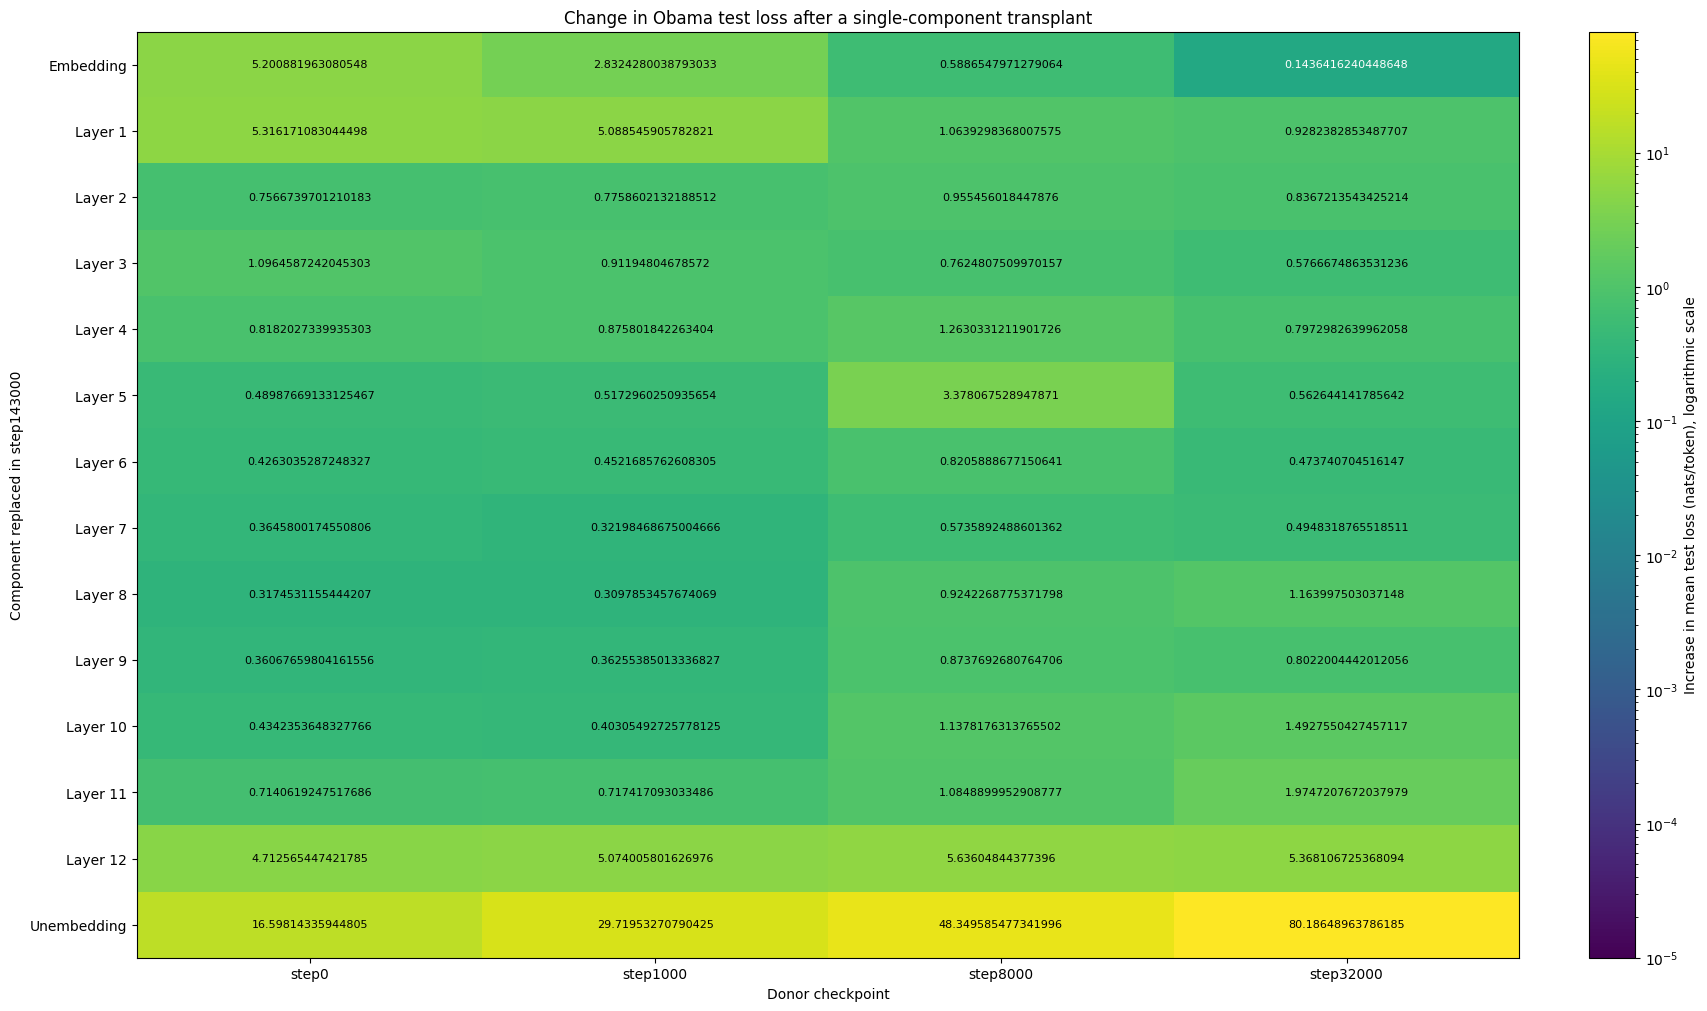

In [30]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

loss_changes = transplant_losses - baseline_loss

color_floor = 1e-5
color_values = np.maximum(loss_changes, color_floor)
color_ceiling = max(float(color_values.max()), color_floor * 10)

fig, ax = plt.subplots(figsize=(17, 10), layout="constrained")
image = ax.imshow(
    color_values,
    cmap="viridis",
    norm=LogNorm(vmin=color_floor, vmax=color_ceiling),
    aspect="auto",
)

ax.set_xticks(range(len(donor_steps)), donor_steps)
ax.set_yticks(range(len(component_names)), component_names)
ax.set_xlabel("Donor checkpoint")
ax.set_ylabel("Component replaced in step143000")
ax.set_title("Change in Obama test loss after a single-component transplant")

for row in range(len(component_names)):
    for column in range(len(donor_steps)):
        value = float(loss_changes[row, column])
        brightness = image.norm(color_values[row, column])
        ax.text(
            column,
            row,
            repr(value),
            ha="center",
            va="center",
            fontsize=8,
            color="black" if brightness > 0.65 else "white",
        )

fig.colorbar(
    image,
    ax=ax,
    label="Increase in mean test loss (nats/token), logarithmic scale",
)

plt.show()


With step0 replacements, the model tolerates losing individual middle layers best. Layer 8 produces the smallest loss increase, 0.317 nats/token, followed by Layers 9 and 7 at 0.361 and 0.365. These changes are relatively small compared with replacing the embedding (+5.201), Layer 1 (+5.316), or Layer 12 (+4.713). The unembedding is the most critical component under this intervention, increasing loss by 16.598, from the intact baseline of 3.373 to 19.971 nats/token.

Later donors do not always cause less damage. The embedding becomes progressively more compatible, with loss increases falling from 5.201 → 2.832 → 0.589 → 0.144 across the four donors. The unembedding shows the opposite pattern, with increases of 16.598 → 29.720 → 48.350 → 80.186. Several layers also become less compatible with later donors. For example, Layer 11’s increase grows from 0.714 at step0 to 1.975 at step32000, while Layer 5 peaks at 3.378 for step8000 before falling to 0.563 for step32000.

These results suggest that components develop compatibility with the representations and weight scales of the surrounding network during training. An intermediate trained component can therefore disrupt the final model more than its random initialization. The particularly large unembedding changes are consistent with a mismatch between an earlier output projection and the final model’s hidden representations.